In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np

import ROOT
import uproot
import glob
import os

Welcome to JupyROOT 6.28/00


# weights from files

In [3]:


# Path to QCD background files
path_to_bkg = "/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/QCD_new/"

# Initialize dictionary for background cutflows
Bkg_keys = [
 "QCD_HT100to200", "QCD_HT200to300","QCD_HT300to500", "QCD_HT500to700", "QCD_HT700to1000", "QCD_HT1000to1500", "QCD_HT1500to2000", "QCD_HT2000toInf",
]

# Initialize the Bkg dictionary
Bkg = {}
gen_events = {}

for key in Bkg_keys:
    Bkg[key] = []
    gen_events[key] = []

# Read in all cutflow tables for each HT bin and sum nFatJet
for key in Bkg_keys:
    print(key)
    
    # Construct the directory path for the current HT bin
    dir_path = os.path.join(path_to_bkg, key)
    
    # Find all ROOT files in the current directory
    file_pattern = os.path.join(dir_path, "*.root")
    files = glob.glob(file_pattern)

    # Process each file
    for file in files:
        with uproot.open(file) as f:

            # Read MT01FatJetMET data from Events tree and Initial from cutflow
            events = f["mmtree/Events"].arrays(filter_name="MT01FatJetMET")
            Bkg[key].append(events["MT01FatJetMET"])
            inital_events = f["CutFlow"].arrays(filter_name="Initial")

            gen_events[key].append(np.full_like(np.array(events["MT01FatJetMET"]), inital_events["Initial"][0]))

    # Store the summed cutflow and nFatJet in the main dictionary
    Bkg[key] = np.concatenate(Bkg[key])
    gen_events[key] = np.concatenate(gen_events[key])

print("Bkg:", Bkg)
print("Gen events:", gen_events)

QCD_HT100to200
QCD_HT200to300
QCD_HT300to500
QCD_HT500to700
QCD_HT700to1000
QCD_HT1000to1500
QCD_HT1500to2000
QCD_HT2000toInf
Bkg: {'QCD_HT100to200': <Array [-1e+04, -1e+04, ... -1e+04, -1e+04] type='1719866 * float64'>, 'QCD_HT200to300': <Array [-1e+04, -1e+04, ... -1e+04, -1e+04] type='1725967 * float64'>, 'QCD_HT300to500': <Array [-1e+04, 342, -1e+04, ... 521, -1e+04] type='51070574 * float64'>, 'QCD_HT500to700': <Array [562, 791, 553, 398, ... 398, 828, 547] type='33945937 * float64'>, 'QCD_HT700to1000': <Array [657, 586, 682, ... 1.24e+03, 733, 874] type='1553122 * float64'>, 'QCD_HT1000to1500': <Array [1.03e+03, 1.57e+03, ... 1.04e+03, 775] type='1355880 * float64'>, 'QCD_HT1500to2000': <Array [1.63e+03, 1.64e+03, ... 1.52e+03] type='1310547 * float64'>, 'QCD_HT2000toInf': <Array [2.55e+03, 2.06e+03, ... 3.05e+03] type='1404094 * float64'>}
Gen events: {'QCD_HT100to200': array([5978., 5978., 5978., ..., 9813., 9813., 9813.]), 'QCD_HT200to300': array([6182., 6182., 6182., ..., 849

In [8]:
x_sec_bkg = [23500000, 1557000, 323400, 30140, 6310, 1094, 99.38, 20.20]
weight_perbin = {}

events_perbin = []
for key in gen_events:
    events_perbin.append(np.sum(gen_events[key]))

for n,key in enumerate(gen_events):

    weight_perbin[key] = np.full_like(gen_events[key], x_sec_bkg[n]/events_perbin[n] )
    


In [10]:
x_sec_bkg = [23500000, 1557000, 323400, 30140, 6310, 1094, 99.38, 20.20]
weight_perfile = {}

events_perfile = gen_events


for n,key in enumerate(gen_events):
    
    x_sec_per_event = np.full_like(gen_events[key], x_sec_bkg[n])
    weight_perfile[key] = x_sec_per_event / gen_events[key]




In [55]:
len(np.array(Bkg["QCD_HT1000to1500"]))

1355880

In [54]:
len(weight_perbin["QCD_HT1000to1500"])

1355880

In [1]:
for key in Bkg:
    plt.hist(np.array(Bkg[key]), np.array(weight_perbin[key]),range = (0,5000), histtype = "step", density = True, label = f"{key}")

plt.yscale("log")
plt.legend()

NameError: name 'Bkg' is not defined

In [15]:
weight_perfile_tot = []
weight_perbin_tot = []
qcd = []

for key in Bkg:
    qcd.append(Bkg[key])
    weight_perfile_tot.append(weight_perfile[key])
    weight_perbin_tot.append(weight_perbin[key])


qcd = np.concatenate(qcd)
weight_perbin_tot = np.concatenate(weight_perbin_tot)
weight_perfile_tot = np.concatenate(weight_perfile_tot)

Text(0, 0.5, 'a.u.')

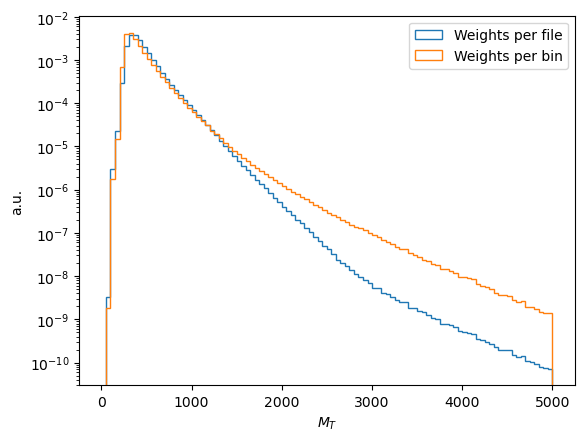

In [25]:
plt.hist(qcd,weights = weight_perfile_tot, histtype = "step",range = (0,5000) ,density = True, bins = 100, label = "Weights per file")
plt.hist(qcd,weights = weight_perbin_tot, histtype = "step", range = (0,5000) ,density = True, bins = 100, label = "Weights per bin")
plt.legend()
plt.yscale('log')
plt.xlabel("$M_{T}$")
plt.ylabel("a.u.")

# MT from graphs (because it is faster than files)

In [3]:
# HT500to700 = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT500to700/processed/QCD_HT500to700_LN5p.pt")
HT700to1000 = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT700to1000/processed/QCD_HT700to1000_LN5p.pt")
HT1000to1500 = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT1000to1500/processed/QCD_HT1000to1500_LN5p.pt")
HT1500to2000 = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT1500to2000/processed/QCD_HT1500to2000_LN5p.pt")
HT2000toInf = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT2000toInf/processed/QCD_HT2000toInf_LN5p.pt")
HT300to500 = torch.load("/pnfs/psi.ch/cms/trivcat/store/user/rhampp/forTraining/Preselection_applied/Bkg_sorted/QCD/QCD_HT300to500/processed/QCD_HT300to500_LN5p.pt")

In [32]:
qcd = []
qcd.append(np.array(HT300to500[0].MT01FatJetMET))
# qcd.append(np.array(HT500to700[0].MT01FatJetMET))
qcd.append(np.array(HT700to1000[0].MT01FatJetMET))
qcd.append(np.array(HT1000to1500[0].MT01FatJetMET))
qcd.append(np.array(HT1500to2000[0].MT01FatJetMET ))
qcd.append(np.array(HT2000toInf[0].MT01FatJetMET))
qcd= np.concatenate(qcd)

In [33]:
## weights from graphs ()

weights_2 = []
weights_2.append(np.array(HT300to500[0].w))
weights_2.append(np.array(HT500to700[0].w))
weights_2.append(np.array(HT700to1000[0].w))
weights_2.append(np.array(HT1000to1500[0].w))
weights_2.append(np.array(HT1500to2000[0].w))
weights_2.append(np.array(HT2000toInf[0].w))
weights_2= np.concatenate(weights_2)

In [34]:
# weights hardcoded

weights_3 = []
n_tot_events = [51070574,	33945937,	1553122,	1355880,	1310547,	1404094]

x_sec = [323400,30140,6310,1094,99.38,20.2]

weights = np.array(x_sec) / np.array(n_tot_events)


weights_3 = [np.full_like(np.array(HT300to500[0].w), weights[0]),
             np.full_like(np.array(HT500to700[0].w), weights[1]),
             np.full_like(np.array(HT700to1000[0].w), weights[2]),
             np.full_like(np.array(HT1000to1500[0].w), weights[3]),
             np.full_like(np.array(HT1500to2000[0].w), weights[4]),
             np.full_like(np.array(HT2000toInf[0].w), weights[5])]
weights_3= np.concatenate(weights_3)

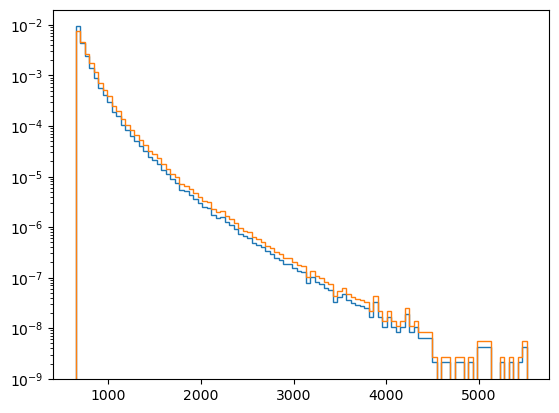

In [35]:
plt.hist(qcd,weights = weights_2, histtype = "step", density = True, bins = 100)
# plt.hist(qcd,weights = weights_2, histtype = "step", density = True, bins = 100 )
plt.hist(qcd,weights = weights_3, histtype = "step", density = True, bins = 100 )

plt.yscale('log')

In [15]:
len(np.array(qcd[0].ht))

114796

In [17]:
ht = np.array(qcd[0].ht)

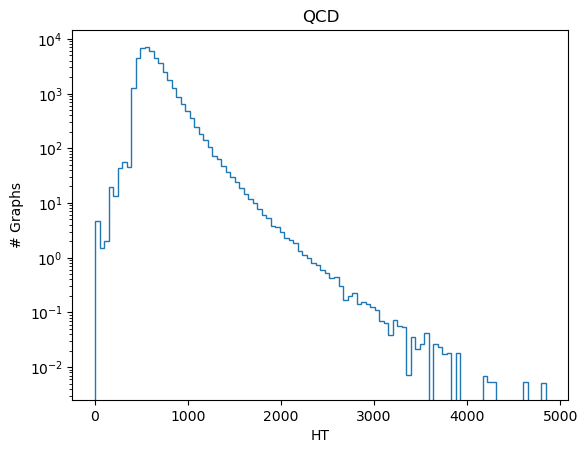

In [19]:
plt.hist(ht, weights = qcd_weights, histtype = 'step', bins = 100)
plt.xlabel("HT")
plt.ylabel("# Graphs")
plt.title("QCD")
plt.yscale('log')


Text(0.5, 1.0, 'QCD')

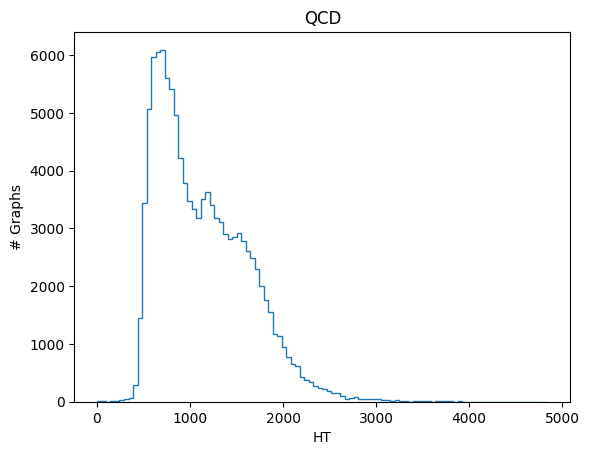

In [9]:
plt.hist(ht, histtype = 'step', bins = 100)
plt.xlabel("HT")
plt.ylabel("# Graphs")
plt.title("QCD")
